# Intro to Computational Science
# Assignment 2
Timothy Böhm - 17068061

Lydia 

# Problem 1

Implementing of Gillespies Direct Method Algorithm

There are 6 events:
 - Birth
 - Infection
 - Recovery
 - Susceptible death
 - Infected death
 - Recovered death

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def gillespie_sir(S0, I0, R0, beta, gamma, mu, t_max, seed=None):
    rng = np.random.default_rng(seed)

    S, I, R = S0, I0, R0
    t = 0.0

    times = [t]
    S_values = [S]
    I_values = [I]
    R_values = [R]

    while t < t_max:
        N = S + I + R

        if N == 0:
            break

        # Rates of the six possible events
        rates = np.array([
            mu * N,           # Birth
            beta * S * I / N, # Infection
            gamma * I,        # Recovery
            mu * S,           # Susceptible death
            mu * I,           # Infected death
            mu * R            # Recovered death
        ])

        total_rate = np.sum(rates)

        if total_rate == 0:
            break

        # Time until the next event
        dt = rng.exponential(1 / total_rate)

        if t + dt > t_max:
            break

        t += dt

        # Choose which event occurs
        event = rng.choice(len(rates), p=rates / total_rate)

        if event == 0:
            S += 1
        elif event == 1:
            S -= 1
            I += 1
        elif event == 2:
            I -= 1
            R += 1
        elif event == 3:
            S -= 1
        elif event == 4:
            I -= 1
        elif event == 5:
            R -= 1

        # Record the updated state
        times.append(t)
        S_values.append(S)
        I_values.append(I)
        R_values.append(R)

    return (
        np.array(times),
        np.array(S_values),
        np.array(I_values),
        np.array(R_values)
    )

Problem 2: Spatial Models - Networks 


Erdos Renyi graph specifies number of nodes and $p$ probability that any pair of nodes is connected. $\bar{k} = p(n - 1)$. 

Watts-Strogatz graph specifies number of nodes and each node connects to approximately $k$ neigbours, each edge has a rewiring probabilty of $p$. 

Barabasi-Albert specifies number of nodes. Every node that enters the network creates $m$ edges to existing nodes. $\bar{k} = 2m$. 


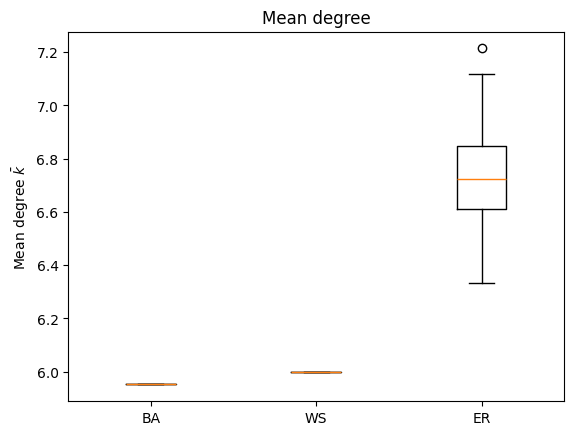

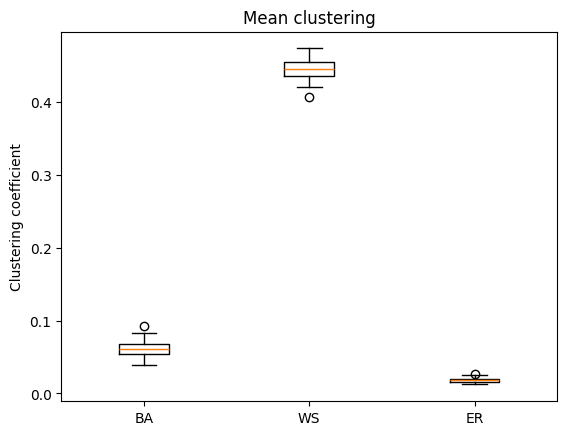

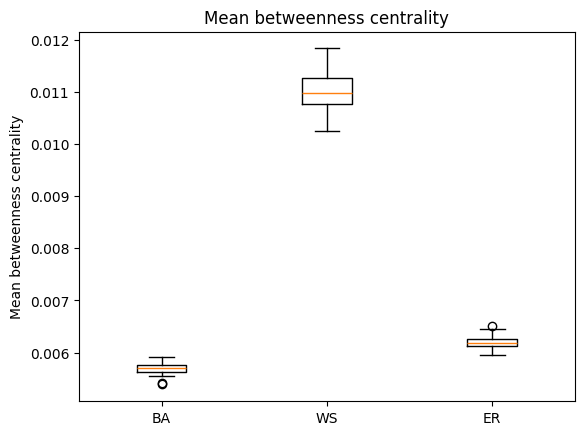

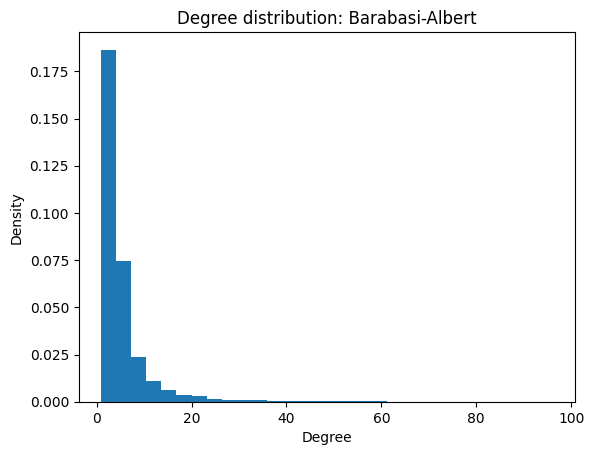

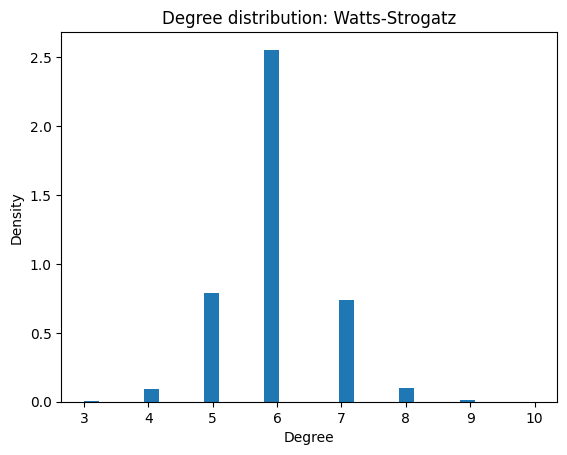

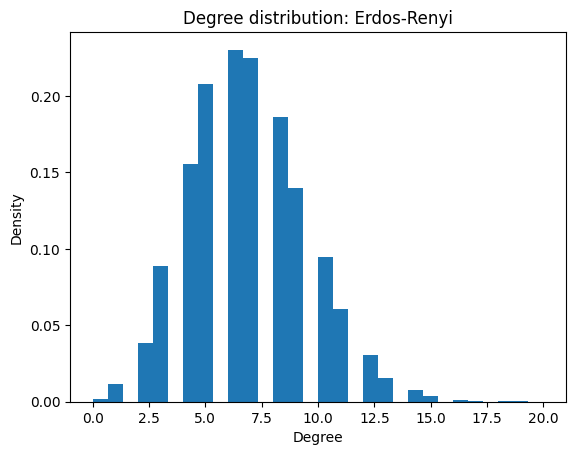

In [14]:
import networkx as nx
import ndlib.models.epidemics as ep
import ndlib.models.ModelConfig as mc
import numpy as np 
import matplotlib.pyplot as plt

#number of nodes
n = 374 

#number of runs 
runs = 100 

#making lists that store network results 
mean_degree = {'BA': [], 'WS': [], 'ER': []}
mean_clustering = {'BA': [], 'WS': [], 'ER': []}
mean_betweenness = {'BA': [], 'WS': [], 'ER': []}
degree_distribution = {'BA': [], 'WS': [], 'ER': []}

for i in range(runs):
    #defining networks with similar properties (374 nodes and a degree between 6 and 7)
    g_ba = nx.barabasi_albert_graph(n = n, m = 3, seed = i)
    g_ws = nx.watts_strogatz_graph(n = n, k = 6, p = 0.1, seed = i)
    g_er = nx.erdos_renyi_graph(n = n, p = 0.018, seed = i)

    network = {'BA': g_ba, 'WS': g_ws, 'ER': g_er}
    
    #get statistics from each network 
    for name, g in network.items():
        degrees = [degree for node, degree in g.degree]
        mean_degree[name].append(np.mean(degrees))
        mean_clustering[name].append(nx.average_clustering(g))
        degree_distribution[name].extend(degrees)
        betweenness = nx.betweenness_centrality(g)
        betweenness_values = list(betweenness.values())
        mean_betweenness[name].append(np.mean(betweenness_values))

#plotting
#mean degree 
network_names = ['BA', 'WS', 'ER']

plt.boxplot([mean_degree['BA'], mean_degree['WS'], mean_degree['ER']],tick_labels=network_names)
plt.title('Mean degree')
plt.ylabel(r'Mean degree $\bar{k}$')
plt.show()


#mean clustering 
plt.boxplot([mean_clustering['BA'], mean_clustering['WS'], mean_clustering['ER']], tick_labels=network_names)
plt.title('Mean clustering')
plt.ylabel('Clustering coefficient')
plt.show()

#mean betweenness
plt.boxplot([mean_betweenness['BA'], mean_betweenness['WS'], mean_betweenness['ER']], tick_labels=network_names)
plt.title('Mean betweenness centrality')
plt.ylabel('Mean betweenness centrality')
plt.show()

#degree distribution BA
plt.hist(degree_distribution['BA'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Barabasi-Albert')
plt.show()

#degree distribution WS
plt.hist(degree_distribution['WS'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Watts-Strogatz')
plt.show()

#degree distribution ER
plt.hist(degree_distribution['ER'], bins=30, density=True)
plt.xlabel('Degree')
plt.ylabel('Density')
plt.title('Degree distribution: Erdos-Renyi')
plt.show()